In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from l0bnb import fit_path
from sklearn.metrics import mean_squared_error

In [2]:
np.random.seed(42)
n = 1000 
p = 20 

X = np.random.randn(n, p)

In [3]:
true_beta = np.zeros(p)
non_zero_indices = np.random.choice(p, size=10, replace=False)
true_beta[non_zero_indices] = np.random.uniform(-10, 10, size=10)

epsilon = np.random.randn(n)

Y = X @ true_beta + epsilon

df = pd.DataFrame(X, columns=[f'X{i+1}' for i in range(p)])
df['Y'] = Y


In [4]:
print(df.head())

         X1        X2        X3        X4        X5        X6        X7  \
0  0.496714 -0.138264  0.647689  1.523030 -0.234153 -0.234137  1.579213   
1  1.465649 -0.225776  0.067528 -1.424748 -0.544383  0.110923 -1.150994   
2  0.738467  0.171368 -0.115648 -0.301104 -1.478522 -0.719844 -0.460639   
3 -0.479174 -0.185659 -1.106335 -1.196207  0.812526  1.356240 -0.072010   
4 -0.219672  0.357113  1.477894 -0.518270 -0.808494 -0.501757  0.915402   

         X8        X9       X10  ...       X12       X13       X14       X15  \
0  0.767435 -0.469474  0.542560  ... -0.465730  0.241962 -1.913280 -1.724918   
1  0.375698 -0.600639 -0.291694  ...  1.852278 -0.013497 -1.057711  0.822545   
2  1.057122  0.343618 -1.763040  ... -0.385082 -0.676922  0.611676  1.031000   
3  1.003533  0.361636 -0.645120  ...  1.538037 -0.035826  1.564644 -2.619745   
4  0.328751 -0.529760  0.513267  ...  0.968645 -0.702053 -0.327662 -0.392108   

        X16       X17       X18       X19       X20          Y  
0 -

In [5]:
X = df.drop("Y", axis = 1)
y = df["Y"]
X = X.to_numpy() if hasattr(X, "to_numpy") else X
y = y.to_numpy() if hasattr(y, "to_numpy") else y

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                   random_state=104, 
                                   test_size=0.1, 
                                   shuffle=True)

In [7]:
path = fit_path(X_train, y_train, max_nonzeros=X.shape[1])

Preprocessing Data.
BnB Started.
Iteration: 1. Number of non-zeros:  1
Iteration: 2. Number of non-zeros:  1
Iteration: 3. Number of non-zeros:  3
Iteration: 4. Number of non-zeros:  3
Iteration: 5. Number of non-zeros:  3
Iteration: 6. Number of non-zeros:  5
Iteration: 7. Number of non-zeros:  5
Iteration: 8. Number of non-zeros:  5
Iteration: 9. Number of non-zeros:  6
Iteration: 10. Number of non-zeros:  6
Iteration: 11. Number of non-zeros:  7
Iteration: 12. Number of non-zeros:  8
Iteration: 13. Number of non-zeros:  9
Iteration: 14. Number of non-zeros:  10
Iteration: 15. Number of non-zeros:  10
Iteration: 16. Number of non-zeros:  10
Iteration: 17. Number of non-zeros:  10
Iteration: 18. Number of non-zeros:  10
Iteration: 19. Number of non-zeros:  10
Iteration: 20. Number of non-zeros:  10
Iteration: 21. Number of non-zeros:  10
Iteration: 22. Number of non-zeros:  10
Iteration: 23. Number of non-zeros:  10
Iteration: 24. Number of non-zeros:  10
Iteration: 25. Number of non-

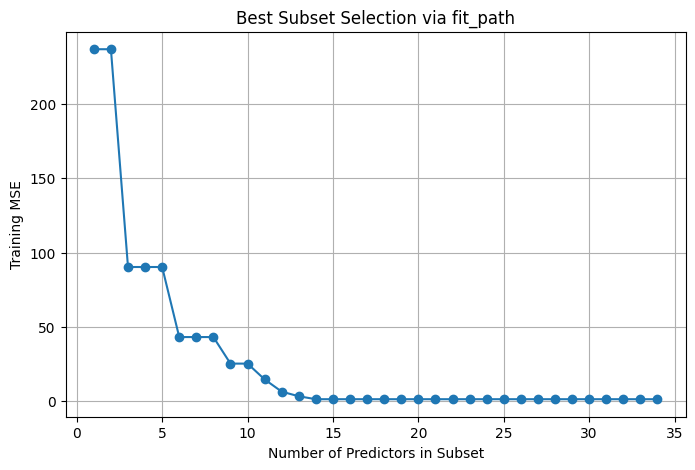

In [8]:
mse_train = []
for result in path:
    y_pred = X_train @ result['B'] + result['B0']
    mse = mean_squared_error(y_train, y_pred)
    mse_train.append(mse)
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(mse_train) + 1), mse_train, marker='o')
plt.xlabel('Number of Predictors in Subset')
plt.ylabel('Training MSE')
plt.title('Best Subset Selection via fit_path')
plt.grid(True)
plt.show()

In [9]:
path[0]

{'B': array([0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 9.7176492, 0.       , 0.       ,
        0.       , 0.       ]),
 'B0': 0.23683606574981306,
 'lambda_0': 0.1456296093810433,
 'M': 0.5370591955112134,
 'Time_exceeded': False}

In [10]:
mse_test = []
for result in path:
    y_pred_test = X_test @ result['B'] + result['B0']
    mse = mean_squared_error(y_test, y_pred_test)
    mse_test.append(mse)

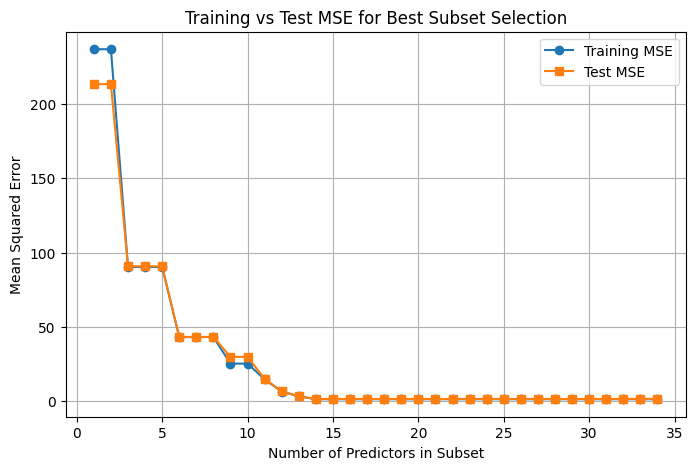

In [12]:
subset_sizes = range(1, len(mse_train) + 1)

plt.figure(figsize=(8, 5))
plt.plot(subset_sizes, mse_train, marker='o', label='Training MSE')
plt.plot(subset_sizes, mse_test, marker='s', label='Test MSE')
plt.xlabel('Number of Predictors in Subset')
plt.ylabel('Mean Squared Error')
plt.title('Training vs Test MSE for Best Subset Selection')
plt.legend()
plt.grid(True)
plt.show()